In [1]:
#!/usr/bin/env python3
# coding: utf-8

"""
File: optimization_support.py
Author: Matthew Ogden
Email: ogdenm12@gmail.com
Github: mbogden
Created: 2024-Nov-11

Description:  This file contains support modules for optmization processes.
    Such as bounding, normalizing, and transforming the input and output space for black-box functions.
    It also abstracts the parallelization of any black-box functions.  

References:  Sections of this code were enhanced with the assistance of ChatGPT made by OpenAI.
"""

# ================================ STANDARD IMPORTS ================================ #
import logging
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# partial imports
from mpi4py import MPI
from skopt import Optimizer
from skopt.space import Real
from skopt.sampler import Lhs, Sobol

# ================================ PROJECT MODULES ================================ #
# Add main project directory to import project modules
try:
    SCRIPT_DIRECTORY = os.path.dirname(os.path.realpath(__file__))
    PROJECT_DIRECTORY = os.path.dirname(SCRIPT_DIRECTORY)
    sys.path.append(PROJECT_DIRECTORY)

except:
    # Assume we are running from the script directory
    SCRIPT_DIRECTORY = os.getcwd()
    PROJECT_DIRECTORY = os.path.dirname(SCRIPT_DIRECTORY)
    
    # Also assume you might be in galStuff
    work_dir = os.getcwd()
    if 'galStuff' == work_dir.split('/')[-1]:
        PROJECT_DIRECTORY =  work_dir + '/galaxyJSPAM'
        sys.path.append(PROJECT_DIRECTORY)

# import project modules
import utilities.general_utility as gu
import utilities.parallel_queue_manager as qm

# ================================ GLOBAL VARIABLES ================================ #
buildEnv = False

# Global logger from main program
SCRIPTS_ARGUMENTS, logger = gu.initialize_environment(module_name='optimizer') # Testing using multiple loggers for tiered log levels.
# SCRIPTS_ARGUMENTS, logger = gu.initialize_environment(module_name='') 

# Generate random instance
rng = np.random.default_rng()

Matplotlib created a temporary config/cache directory at /tmp/matplotlib-njx5c8w1 because the default path (/home/jovyan/.cache/matplotlib) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [2]:
# Development Cell:  This should only be present in the Jupyter Notebook version of this script for development purposes.
buildEnv = True

from importlib import reload

# Warn user if NOT in jupyter notebook, require a yes/no response to continue or not
if "ipykernel" not in sys.modules:
    msg = "Development Environment Detected.  This will run several tests and attempt to creat plots.  Do you want to continue?..."

    # Get user input
    while True:
        response = input(f"{msg} (y/n): ").lower()
        if response in ['y', 'yes']:
            break
        elif response in ['n', 'no']:
            print("Exiting...")
            sys.exit()
        else:
            print("Invalid input. Please enter 'y' or 'n'.")



[2025-03-14 11:12:39,528 - INFO - 2503295286.optimizer.test_space_manager]: Testing Space Manager
[2025-03-14 11:12:39,530 - INFO - 2503295286.Space_Manager.__init__]: Initializing Space Manager
[2025-03-14 11:12:39,535 - INFO - 2503295286.Space_Manager.__init__]: Space Manager Initialized
[2025-03-14 11:12:39,688 - INFO - 2503295286.optimizer.hist_samples]: Histogram Samples
[2025-03-14 11:12:39,688 - INFO - 2503295286.optimizer.hist_samples]: Space Names: ['uni-orig', 'uni-norm', 'log-orig', 'log-norm']
[2025-03-14 11:12:39,689 - INFO - 2503295286.optimizer.hist_samples]: [ 3.41e+00 -9.14e+01  4.69e+01  1.93e-01] - Original Samples
[2025-03-14 11:12:39,690 - INFO - 2503295286.optimizer.hist_samples]: [ 6.44e+01  4.56e-01 -7.90e-01  7.75e-01] - Normalized Samples



Testing Space Manager with Input Space:
{'name': 'uni-orig', 'type': 'float', 'bounds': [-100, 100], 'prior': 'uniform', 'transform': 'identity'}
{'name': 'uni-norm', 'type': 'float', 'bounds': [-100, 100], 'prior': 'uniform', 'transform': 'normalize'}
{'name': 'log-orig', 'type': 'float', 'bounds': [0.01, 100], 'prior': 'log-uniform', 'transform': 'identity'}
{'name': 'log-norm', 'type': 'float', 'bounds': [0.01, 100], 'prior': 'log-uniform', 'transform': 'normalize'}

Random Samples


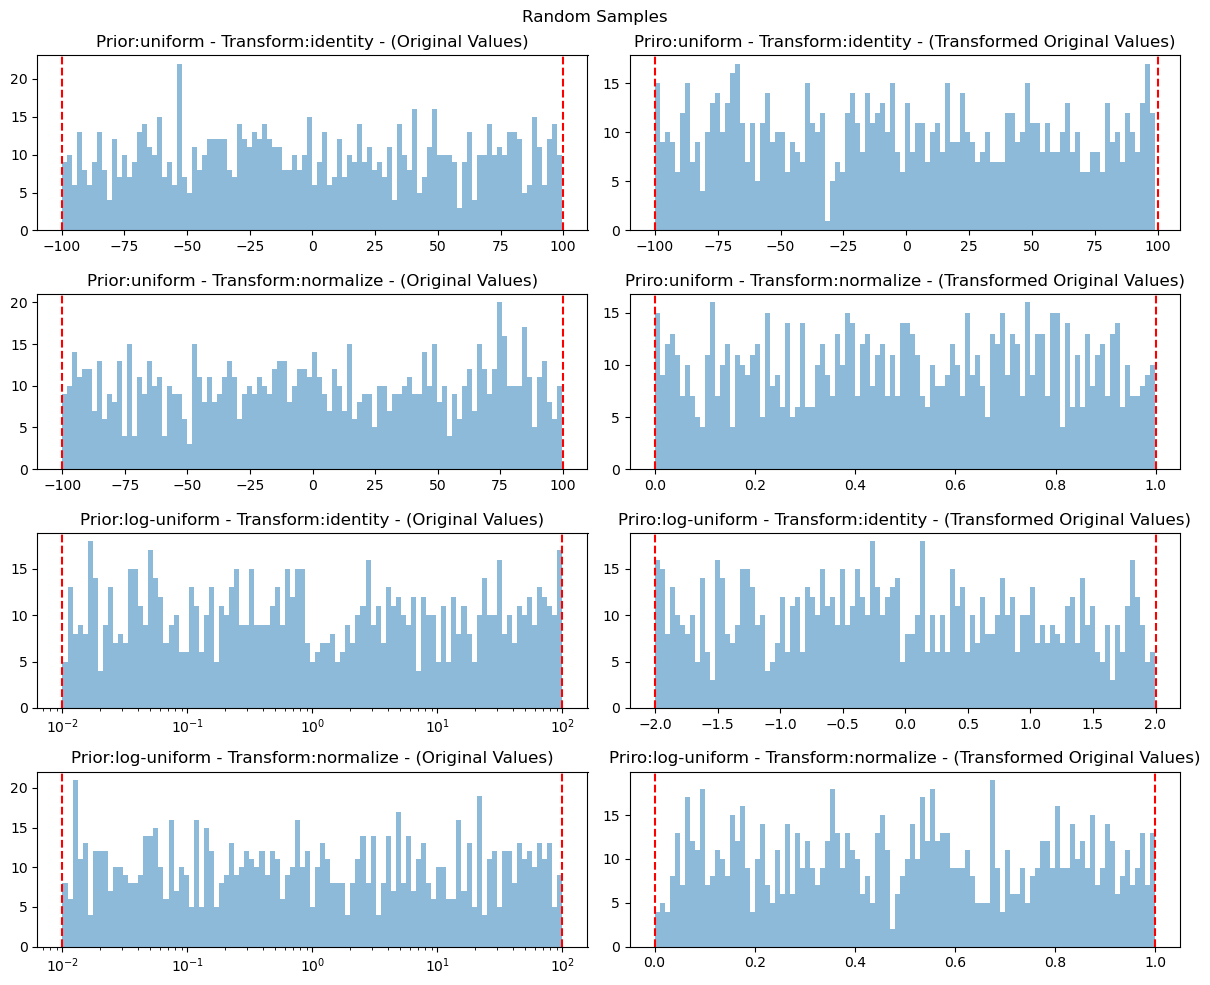

[2025-03-14 11:12:42,931 - INFO - 2503295286.optimizer.hist_samples]: Histogram Samples
[2025-03-14 11:12:42,932 - INFO - 2503295286.optimizer.hist_samples]: Space Names: ['uni-orig', 'uni-norm', 'log-orig', 'log-norm']
[2025-03-14 11:12:42,933 - INFO - 2503295286.optimizer.hist_samples]: [-1.00e+02 -1.00e+02  1.00e-02  1.00e-02] - Original Samples
[2025-03-14 11:12:42,934 - INFO - 2503295286.optimizer.hist_samples]: [-1.00e+02  0.00e+00 -2.00e+00  0.00e+00] - Normalized Samples


Grid Samples


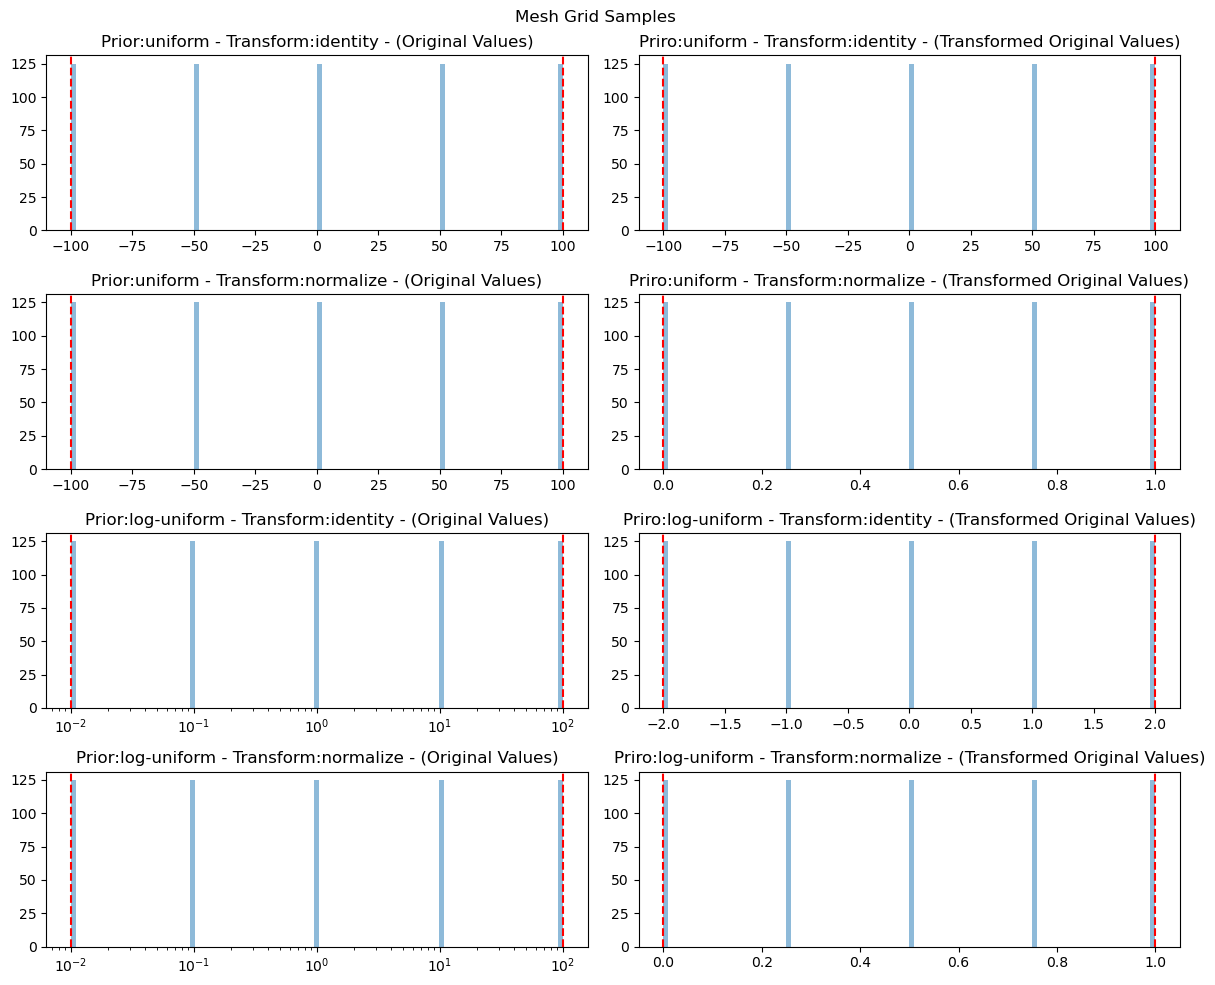

[2025-03-14 11:12:45,470 - INFO - 2503295286.optimizer.hist_samples]: Histogram Samples
[2025-03-14 11:12:45,472 - INFO - 2503295286.optimizer.hist_samples]: Space Names: ['uni-orig', 'uni-norm', 'log-orig', 'log-norm']
[2025-03-14 11:12:45,473 - INFO - 2503295286.optimizer.hist_samples]: [-2.75e+00 -7.82e+01  7.53e-02  3.00e+01] - Original Samples
[2025-03-14 11:12:45,474 - INFO - 2503295286.optimizer.hist_samples]: [ 8.15e+00  7.17e-02 -1.24e+00  4.05e-01] - Normalized Samples


LHS Samples


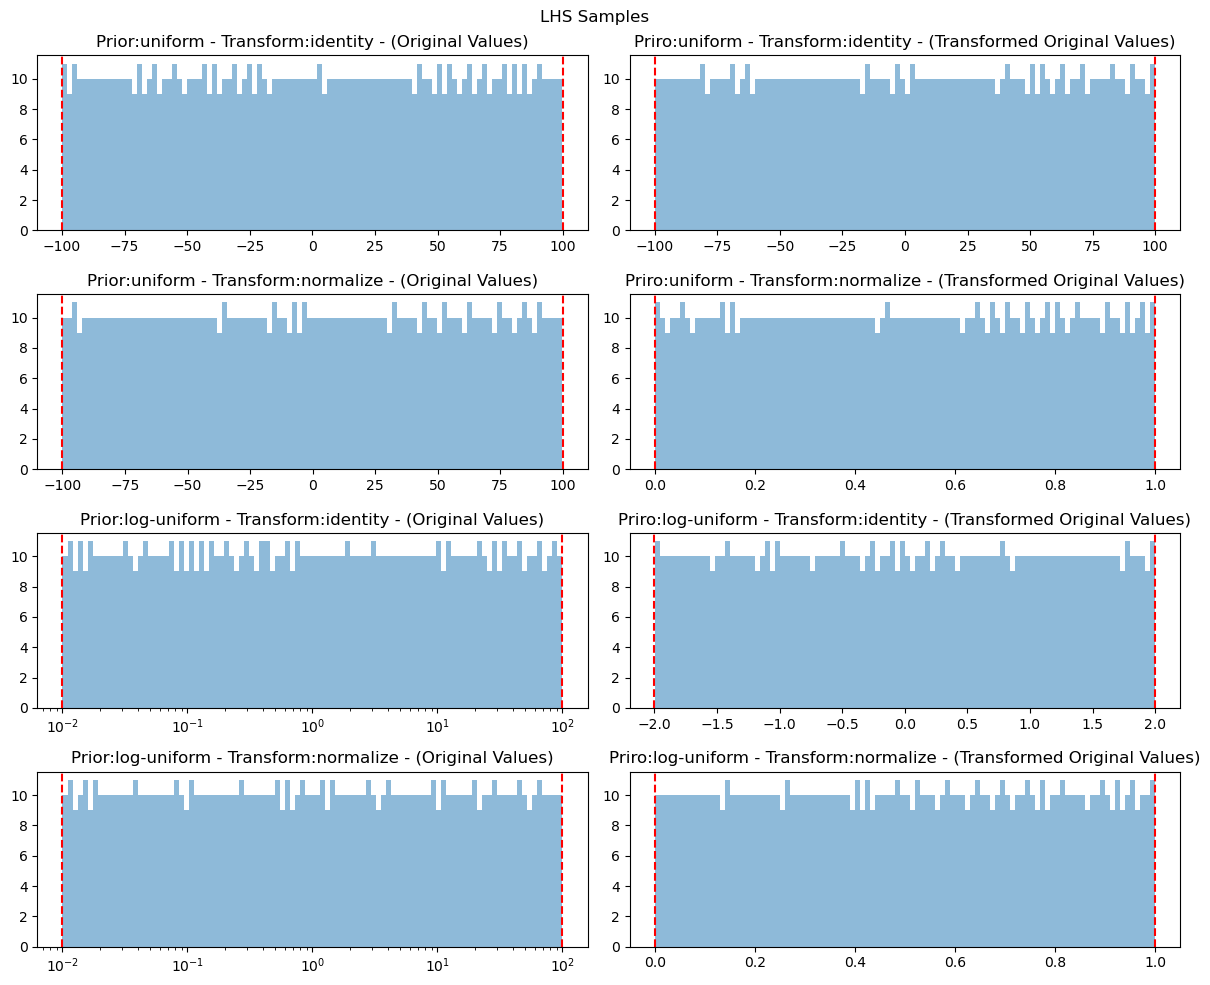

/home/mbo2d/.local/lib/python3.10/site-packages/skopt/sampler/sobol.py:521: UserWarning: The balance properties of Sobol' points require n to be a power of 2. 0 points have been previously generated, then: n=0+1000=1000. 
  warnings.warn(
/home/mbo2d/.local/lib/python3.10/site-packages/skopt/sampler/sobol.py:521: UserWarning: The balance properties of Sobol' points require n to be a power of 2. 0 points have been previously generated, then: n=0+1000=1000. 
  warnings.warn(
[2025-03-14 11:12:48,062 - INFO - 2503295286.optimizer.hist_samples]: Histogram Samples
[2025-03-14 11:12:48,063 - INFO - 2503295286.optimizer.hist_samples]: Space Names: ['uni-orig', 'uni-norm', 'log-orig', 'log-norm']
[2025-03-14 11:12:48,064 - INFO - 2503295286.optimizer.hist_samples]: [-5.33e+01 -5.45e+01  3.20e-01  5.35e-02] - Original Samples
[2025-03-14 11:12:48,065 - INFO - 2503295286.optimizer.hist_samples]: [-3.32e+01  3.58e-01  4.33e-01  9.29e-01] - Normalized Samples


Sobol Samples


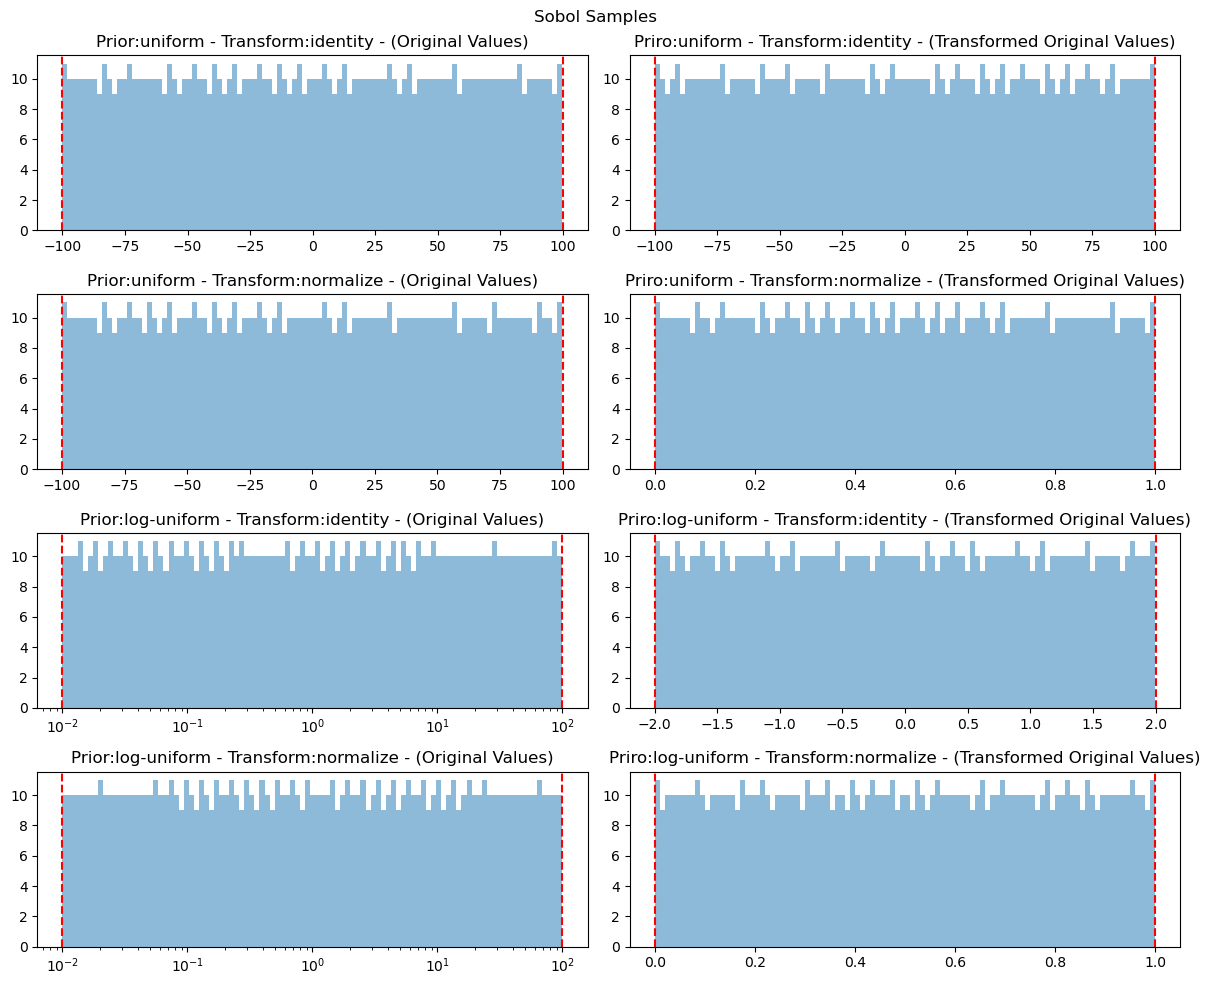

In [ ]:
class Space_Manager:
    '''
    Class to manage the input space between black-box functions 
    and algorithms that benefit from normalized variables.
    All variables are handled as `Real` for simplicity.
    '''

    def __init__(self, space_info, log_level=logging.INFO):
        """ Initialize the search space with variable details. """
        self.logger = gu.configure_logger( logger_name = 'Space_Manager', log_level = log_level )
        self.logger.info(f"Initializing Space Manager")
        self.space_info = space_info  # Assume space info is a list of dictionaries
        self.space = self._create_space()
        self.version = 1  # Initialize versioning for space updates
        self.space_record = {} # for storing space details over multiple versions
        self.space_record[self.version] = self.space_info
        self.logger.info(f"Space Manager Initialized")
    # end of __init__

    def get_space(self):
        return self.space_info
    # end of get_space

    def _create_space(self):
        """Creates and initializes the search space with optional transformations."""

        self.logger.info(f"Creating search space")

        space = []
        for i,var_info in enumerate(self.space_info):

            var_name = var_info['name']  # Required
            self.logger.debug(f"Creating variable: {var_name}")

            # Extract basic attributes
            bounds = var_info.get('bounds', None)  # Required
            prior = var_info.get('prior', 'uniform')  # Default to uniform, used for sampling
            transform = var_info.get('transform', 'identity')  # Default to identity, used for normalization
            meta = var_info.get('meta', {})  # Meta-information (optional)
            self.logger.debug( f"Variable: {var_name} - Bounds: {bounds} - Prior: {prior} - Transform: {transform}")

            # Most types require bounds
            if bounds is None:
                raise ValueError(f"Bounds are required for variable type: {var_name}")

            # Handle Real variable types with transformation
            if transform in ['normalize', 'identity']:
                # If standard transforms (normalize or identity)
                dimension = Real(bounds[0], bounds[1], prior=prior, name=var_name, transform=transform)

                # generate transformed bounds
                dimension.transformed_bounds_ = [dimension.transform(bounds[0]), dimension.transform(bounds[1])]

            else:
                raise ValueError(f"Unsupported transform type: {transform}")
        
            self.logger.debug(f"Transformed Bounds: {dimension.transformed_bounds_}")

            # Attach meta-information for reference
            if meta:
                dimension.meta = meta  # Store meta info as an attribute
            else:
                dimension.meta = None

            space.append( dimension )

            # Add everything to the space info
            self.space_info[i]['prior'] = prior
            self.space_info[i]['transform'] = transform
            self.space_info[i]['transformed_bounds'] = dimension.transformed_bounds_

        return space
    # end of _create_space

    def update_space(self, space_info):
        """Update the search space with new bounds, variables or transformations."""
        self.space_info = space_info
        self.space = self._create_space()
        self.version += 1
    # end of update_space

    def transform_points(self, points, inverse=False):
        """
        Transforms points from original space to normalized space or vice-versa.
        points: np.ndarray of shape (n_points, n_dims)        
        """

        # If there's a single point, add a dummy axis to make it a batch of one
        if len(points.shape) == 1:
            points = points.reshape(1, -1)
        
        # iterate over columns
        for i in range(points.shape[1]):

            # Apply transformation
            if inverse:
                points[:, i] = self.space[i].inverse_transform(points[:, i])
            else:
                points[:, i] = self.space[i].transform(points[:, i])
            
        if len(points) == 1:
            return points[0]
        else:
            return points
    # end of transform_points

    def get_random_sample( self, n_samples = 3, space='normalized', shuffle=True ):
        """ Get random samples from the search space. """

        samples = np.zeros((n_samples, len(self.space_info)))
        for i, dim in enumerate(self.space):
            samples[:, i] = dim.rvs(n_samples)
        
        if shuffle:
            np.random.permutation(samples)

        if space == 'normalized':
            return self.transform_points(samples)
        else:        
            return samples
    # end of get_random_sample

    def get_mesh_grid_points( self, n_pts_per_dim = 5, space='normalized', shuffle=True ):
        """ Generate mesh grid points for the search space. """

        # Select values along each dimension
        grids = []
        for dim in self.space:
            if dim.prior == 'uniform':
                grids.append(np.linspace(dim.low, dim.high, num=n_pts_per_dim))
            if dim.prior == 'log-uniform':
                grids.append(np.logspace(np.log10(dim.low), np.log10(dim.high), num=n_pts_per_dim))

        # Generate grid points
        grid_points = np.array(np.meshgrid(*grids)).T.reshape(-1, len(self.space))

        if shuffle:
            np.random.permutation(grid_points)

        if space == 'original':
            return grid_points
        else:
            return self.transform_points(grid_points)
    # end of get_mesh_grid_points
           
    def get_lhs_samples( self, n_samples = 10, space='normalized', shuffle=True ):
        """ Get Latin Hypercube samples from the search space. """

        lhs = Lhs(lhs_type="classic", criterion=None)
        samples = np.array( lhs.generate(self.space, n_samples) )
        
        if shuffle:
            np.random.permutation(samples)

        if space == 'normalized':
            return self.transform_points(samples)
        else:
            return samples
    # end of get_lhs_samples

    def get_sobol_samples(self, n_samples=10, space='normalized', shuffle=True):
        """Get Sobol samples from the search space."""

        sampler = Sobol()
        sobol_samples = np.array(sampler.generate(self.space, n_samples))

        if shuffle:
            np.random.permutation(sobol_samples)

        if space == 'normalized':
            return self.transform_points(sobol_samples)
        else:
            return sobol_samples
    # end of get_sobol_samples

    def save_space_details(self, file_path):
        """Save the dimension details to a JSON file."""
        import json

        json.dump(self.space_info, open(file_path, 'w'), indent=2)
    # end of save_space_details
    
# end of SpaceManager class

def hist_samples( o_samples, n_samples, space_info, manager, title='Histograme Samples' ):

    # Create plots with 4 subpltos
    import matplotlib.pyplot as plt
    fig, axs = plt.subplots(len(space_info), 2, figsize=(12, 10))
    # fig, axs = plt.subplots(len(space_info), 4, figsize=(24, 10))
    
    # set main title
    fig.suptitle(title)

    # Turn off debug logging for matplotlib
    plt.rcParams['figure.max_open_warning'] = 0

    # Check if transform works
    ot_samples = manager.transform_points(np.copy(o_samples))
    nt_samples = manager.transform_points(np.copy(n_samples), inverse=True)

    logger.info("Histogram Samples")
    logger.info(f"Space Names: {[var_info['name'] for var_info in space_info]}")
    logger.info(f"{o_samples[0]} - Original Samples")
    # logger.info(f"{ot_samples[0]} - Transformed Original Samples")
    
    logger.info(f"{n_samples[0]} - Normalized Samples")
    # logger.info(f"{nt_samples[0]} - Transformed Normalized Samples")

    logger.setLevel(logging.INFO)

    for i, var_info in enumerate(space_info):
        var_name = var_info['name']
        # print(f"\nVariable: {var_name}")
        # Add to first subplot
        if var_info['prior'] == 'log-uniform':
            # Bin with log scaling
            axs[i, 0].set_xscale('log')
            axs[i, 0].hist(o_samples[:, i], bins=np.logspace(np.log10(var_info['bounds'][0]), np.log10(var_info['bounds'][1]), 100), alpha=0.5, label='Original')
        
        else:
            axs[i, 0].hist(o_samples[:, i], bins=100, alpha=0.5, label='Original')

        # axs[i, 2].hist(ot_samples[:, i], bins=100, alpha=0.5, label='Transformed Original')
        # axs[i, 3].hist(nt_samples[:, i], bins=100, alpha=0.5, label='Transformed Normalized')

        axs[i, 1].hist(n_samples[:, i], bins=100, alpha=0.5, label='Normalized')
        
        axs[i, 0].set_title(f"Prior:{var_info['prior']} - Transform:{var_info['transform']} - (Original Values)")
        axs[i, 1].set_title(f"Priro:{var_info['prior']} - Transform:{var_info['transform']} - (Transformed Original Values)")

        # Add bounds to the plot
        axs[i, 0].axvline(var_info['bounds'][0], color='r', linestyle='--')
        axs[i, 0].axvline(var_info['bounds'][1], color='r', linestyle='--')

        try:
            axs[i, 1].axvline(manager.space[i].transformed_bounds_[0], color='r', linestyle='--')
            axs[i, 1].axvline(manager.space[i].transformed_bounds_[1], color='r', linestyle='--')
        except:
            pass
    
    # logger.setLevel(logging.DEBUG)
    
    # tight layout
    plt.tight_layout()
    plt.show()


def test_space_manager():
    logger.info(f"Testing Space Manager")

    logger.setLevel(logging.INFO)

    space_transform_test = [
        {'name':'uni-orig', 'type': 'float', 'bounds': [-100, 100], 'prior':'uniform', 'transform':'identity'  }, # Working
        {'name':'uni-norm', 'type': 'float', 'bounds': [-100, 100], 'prior':'uniform', 'transform':'normalize' }, # Working
        {'name':'log-orig', 'type': 'float', 'bounds': [1e-2, 100], 'prior':'log-uniform', 'transform':'identity' }, # Working
        {'name':'log-norm', 'type': 'float', 'bounds': [1e-2, 100], 'prior':'log-uniform', 'transform':'normalize' }, # Working
    ]
    
    print("\nTesting Space Manager with Input Space:")
    for var_info in space_transform_test:
        print(var_info)
    # gu.pp(space_transform_test)
    print('')

    manager = Space_Manager(space_transform_test)

    manager.save_space_details('test_space_details.json')

    n = 1000
    o_samples = manager.get_random_sample(n, space='original') # original samples
    n_samples = manager.get_random_sample(n, space='normalized') # normalized samples
    
    print("Random Samples")
    hist_samples( o_samples, n_samples, space_transform_test, manager, title='Random Samples' )

    if True:

        # Do the same with gridsearch
        o_samples = manager.get_mesh_grid_points(5, space='original') # original samples
        n_samples = manager.get_mesh_grid_points(5, space='normalized') # normalized samples
        print("Grid Samples")
        hist_samples( o_samples, n_samples, space_transform_test, manager, title='Mesh Grid Samples' )

        # Do the same with LHS
        o_samples = manager.get_lhs_samples(n, space='original') # original samples
        n_samples = manager.get_lhs_samples(n, space='normalized') # normalized samples
        print("LHS Samples")
        hist_samples( o_samples, n_samples, space_transform_test, manager, title='LHS Samples' )

        # Do the same with Sobol
        o_samples = manager.get_sobol_samples(n, space='original') # original samples
        n_samples = manager.get_sobol_samples(n, space='normalized') # normalized samples
        print("Sobol Samples")
        hist_samples( o_samples, n_samples, space_transform_test, manager, title='Sobol Samples' )

if buildEnv:
    # Set numpy precision print with arrays as sci format with 3 decimals w space for sign
    np.set_printoptions(precision=3, suppress=True, formatter={'all': lambda x: f'{x: 0.2e}'})
    test_space_manager()

[2025-03-14 11:12:51,187 - INFO - 2119265034.optimizer.<module>]: My Current log level is 'DEBUG'
[2025-03-14 11:12:51,188 - INFO - 2119265034.optimizer.<module>]: Function Logger is at 'INFO'
[2025-03-14 11:12:51,189 - INFO - 2119265034.optimizer.<module>]: Having test module call print log function
[2025-03-14 11:12:51,192 - INFO - parallel_queue_manager.Queue_Manager._set_local_mode]: Local Manager initialized with 32 workers using local multiprocessing (futures).


Creating a new logger for testing the test function
You should see function calls
test print: 3test print: 2test print: 4



[2025-03-14 11:12:51,618 - ERROR - 2119265034.test_logger.testing_logger]: Error: 3


[2025-03-14 11:12:51,619 - CRITICAL - 2119265034.test_logger.testing_logger]: Critical: 3
[2025-03-14 11:12:51,619 - ERROR - 2119265034.test_logger.testing_logger]: Error: 2
[2025-03-14 11:12:51,620 - DEBUG - 2119265034.optimizer.testing_logger]: Std Logger Debug: 3
[2025-03-14 11:12:51,621 - CRITICAL - 2119265034.test_logger.testing_logger]: Critical: 2
[2025-03-14 11:12:51,620 - ERROR - 2119265034.test_logger.testing_logger]: Error: 4
[2025-03-14 11:12:51,622 - CRITICAL - 2119265034.test_logger.testing_logger]: Critical: 4
[2025-03-14 11:12:51,622 - DEBUG - 2119265034.optimizer.testing_logger]: Std Logger Debug: 2
[2025-03-14 11:12:51,623 - DEBUG - 2119265034.optimizer.testing_logger]: Std Logger Debug: 4
[2025-03-14 11:12:51,626 - INFO - parallel_queue_manager.Queue_Manager._run_local_processes]: Local Manager: Progress: [====================] 3/3 - Queue Complete
[2025-03-14 11:12:51,628 - INFO - 2119265034.optimizer.<module>]: Results: [4, 6, 8]
[2025-03-14 11:12:51,630 - INFO - 2

test print: 5


test print: [-2.23e-02]test print: [-1.02e+00]test print: [-3.25e+00]test print: [ 2.37e-02]





[2025-03-14 11:12:52,139 - ERROR - 2119265034.test_logger.testing_logger]: Error: [-2.23e-02]
[2025-03-14 11:12:52,140 - ERROR - 2119265034.test_logger.testing_logger]: Error: [-1.02e+00]
[2025-03-14 11:12:52,140 - ERROR - 2119265034.test_logger.testing_logger]: Error: [-3.25e+00]
[2025-03-14 11:12:52,140 - ERROR - 2119265034.test_logger.testing_logger]: Error: [ 2.37e-02]
[2025-03-14 11:12:52,141 - CRITICAL - 2119265034.test_logger.testing_logger]: Critical: [-2.23e-02]
[2025-03-14 11:12:52,142 - CRITICAL - 2119265034.test_logger.testing_logger]: Critical: [-3.25e+00]
[2025-03-14 11:12:52,142 - CRITICAL - 2119265034.test_logger.testing_logger]: Critical: [-1.02e+00]
[2025-03-14 11:12:52,142 - CRITICAL - 2119265034.test_logger.testing_logger]: Critical: [ 2.37e-02]
[2025-03-14 11:12:52,143 - DEBUG - 2119265034.optimizer.testing_logger]: Std Logger Debug: [-2.23e-02]
[2025-03-14 11:12:52,144 - DEBUG - 2119265034.optimizer.testing_logger]: Std Logger Debug: [-3.25e+00]
[2025-03-14 11:12:


Testing Input Space:
{'name': 'uni-orig', 'type': 'float', 'bounds': [-4, 4], 'prior': 'uniform', 'transform': 'identity'}
{'name': 'log-orig', 'type': 'float', 'bounds': [0.01, 4], 'prior': 'log-uniform', 'transform': 'identity'}
{'name': 'uni-norm', 'type': 'float', 'bounds': [-4, 4], 'prior': 'uniform', 'transform': 'normalize'}
{'name': 'log-norm', 'type': 'float', 'bounds': [0.01, 4], 'prior': 'log-uniform', 'transform': 'normalize'}

Test Function: Sum of Squares (sum(x^2))


[2025-03-14 11:12:53,183 - INFO - parallel_queue_manager.Queue_Manager._run_local_processes]: Local Manager: Progress: [================    ] 817/1000
[2025-03-14 11:12:53,253 - INFO - parallel_queue_manager.Queue_Manager._run_local_processes]: Local Manager: Progress: [====================] 1000/1000 - Queue Complete
[2025-03-14 11:12:54,752 - INFO - 2119265034.execution_manager.__del__]: Execution Manager Terminated
[2025-03-14 11:12:54,803 - INFO - parallel_queue_manager.Queue_Manager.__del__]: Queue Manager Deleted


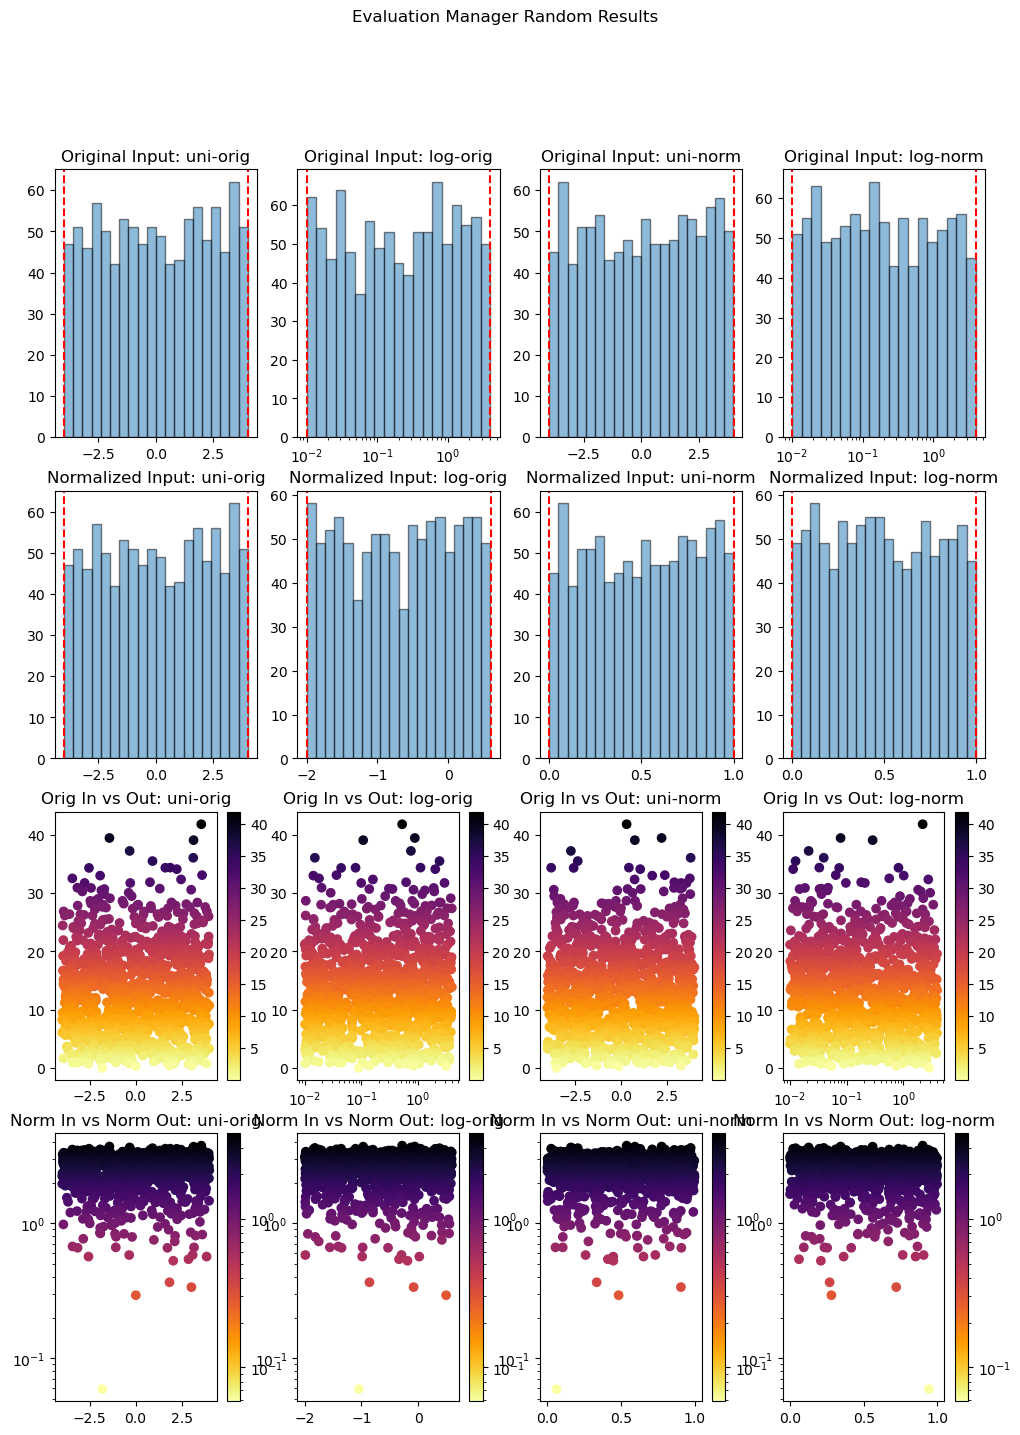

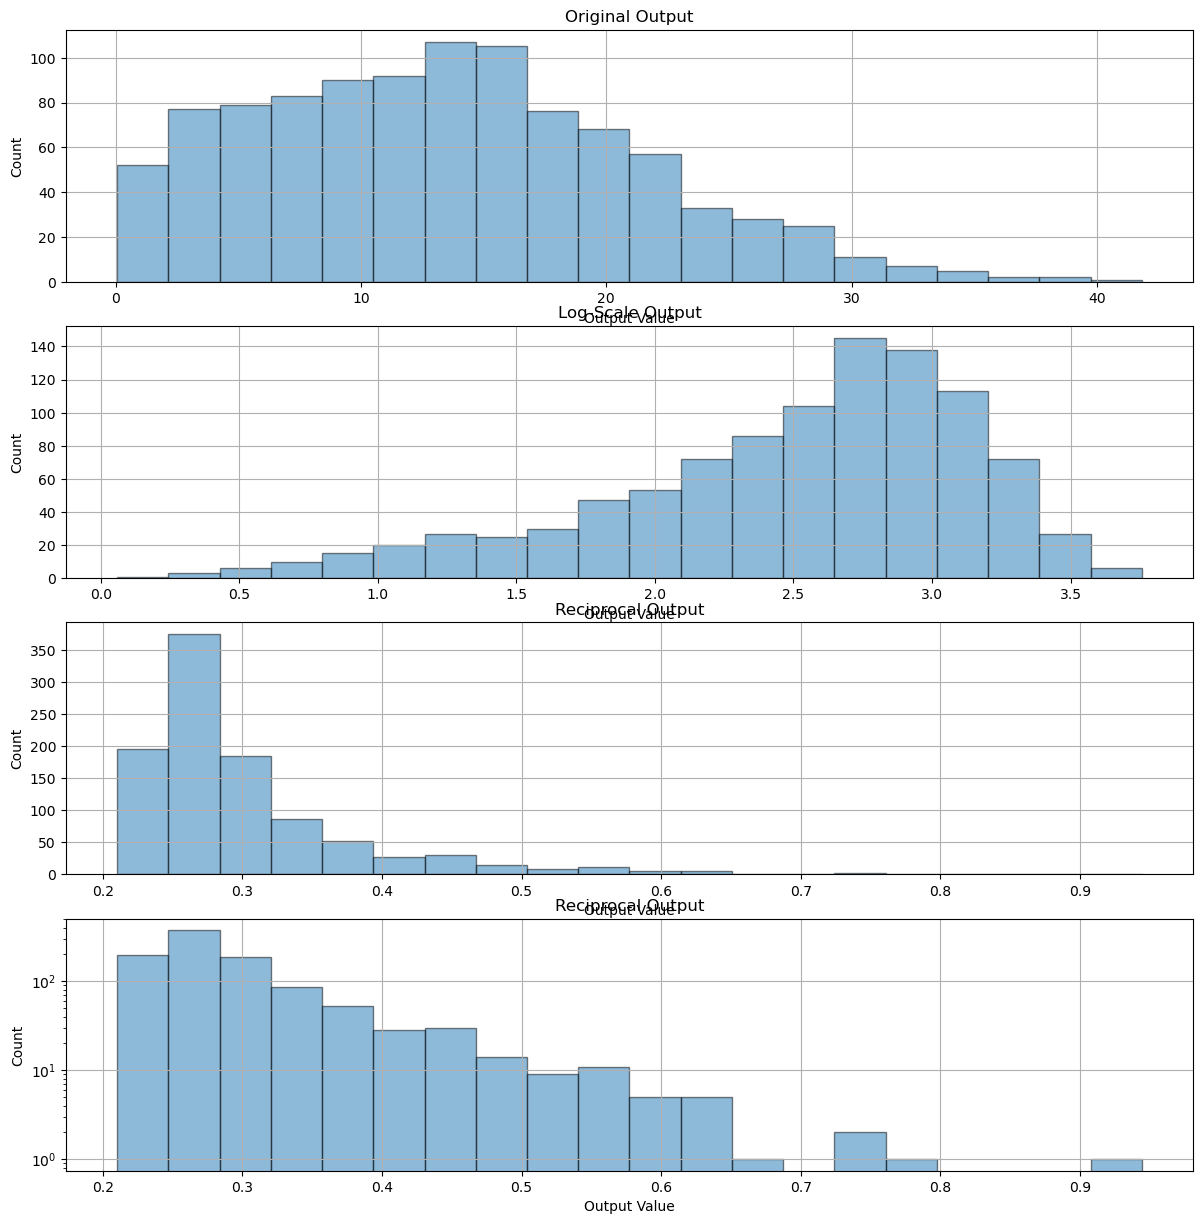

In [ ]:
class Execution_Manager:
    """
    Class to manage the execution of black-box functions in parallel.
    Interfaces with the space manager to handle normalized dimensions.
    Also normalizes the final scores if requested.
    Feeds noramlized inputs and ouputs to higher-level optimization algorithms.
    NOTE: This is intended for computationlly expensive functions.
    """

    def __init__( self, space_manager, black_box_function, normalize_output='original',
                 save_results=True, num_outputs=1, exec_log_level=logging.INFO,
                 func_logger = None, func_log_level = logging.WARNING,
                 ):
        
        """Initialize the execution manager with the function to evaluate."""
        self.logger = gu.configure_logger( logger_name='execution_manager', log_level=exec_log_level )
        self.logger.info(f"Initializing Execution Manager")

        self.save_results = save_results
        self.space_manager = space_manager
        self.n_dims = len(space_manager.space_info)
        self.n_out = num_outputs
        self.x = np.zeros((0, self.n_dims)) # Original Inputs
        self.y = np.zeros((0, self.n_out)) # Original Outputs
        self.xn = np.zeros((0, self.n_dims)) # Normalized Inputs
        self.yn = np.zeros((0, self.n_out)) # Normalized Outputs
        self.bad_x = np.zeros((0, self.n_dims)) # Bad Inputs

        # Generate output normalizer function
        self.gen_output_normalizer(normalize_output)

        # Setup Execution Environment for black box function
        self.function = black_box_function
        if isinstance( func_logger, str ):
            self.func_logger = logging.getLogger(func_logger)
        elif func_logger is None:
            self.func_logger = logging.getLogger('')  # Assume function uses root logger if not provided
        else:
            self.func_logger = func_logger
        self.func_log_level = func_log_level
        self.comm = MPI.COMM_WORLD
        self.rank = self.comm.Get_rank()
        self.size = self.comm.Get_size()

        # Setup Parallel workers to be on standby to process black box function evaluations
        if self.rank != 0:
            self.logger.info(f"Execution Worker on Standby")
            self.queue_manager = qm.Queue_Worker(self.function)
            return
        
        # Else you're the manager. Continue with initialization
        self.queue_manager = qm.Queue_Manager(self.function)

        # Else, you're a manager. Continue with initialization
        self.logger.info(f"Execution Manager Initialized")
        
    # end of __init__

    def __del__(self):
        if self.rank == 0:
            self.queue_manager.terminate_workers()
        self.logger.info(f"Execution Manager Terminated")
    # end of __del__

    def set_function_log_level( self, log_level ):
        """Set the log level for the function logger."""
        self.func_logger.setLevel(log_level)
    # end of set_function_log_level

    def evaluate_function(self, x, space = 'normalized', save_results=None):
        """Evaluate the black-box function for a given list."""
        self.logger.info(f"Evaluating Function: Inputs: {len(x)}")
        self.logger.debug(f"x - {len(x)}: {x[0]}")

        if save_results is None:
            save_results = self.save_results
        
        # Save previous func logger level
        prev_log_level = self.func_logger.level

        # set to new level
        self.func_logger.setLevel(self.func_log_level)

        if space == 'normalized':
            results = self.evaluate_function_normalized(x, save_results)
        elif space == 'original':
            results =  self.evaluate_function_from_original(x, save_results)
               
        # Return to previous level
        self.func_logger.setLevel(prev_log_level)

        return results
    # end of evaluate_function

    def evaluate_function_normalized(self, nx, save_results=None):
        """Evaluate the black-box function for a given list."""

        if save_results is None:
            save_results = self.save_results

        # If x is list, convert to numpy array
        if isinstance(nx, list):
            nx = np.array(nx)

        self.logger.info("Starting Normalized Evaluation of Function")
        self.logger.debug(f"nx.shape{nx.shape} - nx[0]: {nx[0]}")

        # Check if ranges are appropriate
        for i, dim in enumerate(self.space_manager.space):
            min_value = np.amin( nx[:, i] )
            max_value = np.amax( nx[:, i] )
            if  ( ( min_value < dim.transformed_bounds_[0] ) or ( dim.transformed_bounds_[1] < max_value) ):
                self.logger.error(f"Normalized Input Column {i} is out of bounds: [{min_value:.2e}, {max_value:.2e}] not in [{dim.transformed_bounds_[0]}, {dim.transformed_bounds_[1]}]")
                raise ValueError(f"Input Column {i} is out of bounds: [{min_value:.2e}, {max_value:.2e}] not in [min, max] [{dim.low}, {dim.high}]")
        
        # Inverse transform the normalized inputs to orginal space
        x = np.copy(nx)
        x = self.space_manager.transform_points(np.copy(nx), inverse=True)

        # Verify x has the same shape as nx
        if x.shape != nx.shape:
            x = np.reshape(x, nx.shape)

        self.logger.debug(f" x.shape{x.shape} -  x[0]: {x[0]}")
        
        # Add list to the queue and evaluate
        y_raw = self.queue_manager.evaluate_tasks(x)

        # Loop backwards through returns and remove any None values, as well as corresponding x values
        popped_count = 0
        for i in range( len(y_raw) - 1, -1, -1):
            
            # Check if exception value was given
            if isinstance(y_raw[i], Exception):

                # print exception before removing
                self.logger.warning(f"Exception Returned: '{y_raw[i]}'")
                self.bad_x = np.vstack([self.bad_x, x[i]])
                x = np.delete(x, i, axis=0)
                nx = np.delete(nx, i, axis=0)
                y_raw.pop(i)
                popped_count += 1

            elif isinstance(y_raw[i], type(None)):
                self.bad_x = np.vstack([self.bad_x, x[i]])
                x = np.delete(x, i, axis=0)
                nx = np.delete(nx, i, axis=0)
                y_raw.pop(i)
                popped_count += 1

        if popped_count > 0:
            self.logger.warning(f"Removed {popped_count} of {len(x)+popped_count} inputs due to None/Null")
        
        # Check if all evaluations failed
        if len(x) == 0:
            self.logger.error(f"All Executions failed.  Raising error")
            raise ValueError("All Functions Evaluations Failed")
        
        y = np.array( y_raw )

        # Make sure y is 2D
        if len(y.shape) == 1:
            y = y.reshape(-1, self.n_out)

        self.logger.debug(f" y.shape: {y.shape} -  y[0]: {y[0]}")
        ny = self.output_normalizer(y)

        self.logger.debug(f"ny.shape: {ny.shape} - ny[0] {ny[0]}")

        # add retsults to the results array
        if save_results:
            self.x = np.vstack([self.x, x])
            self.y = np.vstack([self.y, y])
            self.xn = np.vstack([self.xn, nx])
            self.yn = np.vstack([self.yn, ny])

        return ny
    # end of evaluate_function

    def evaluate_function_from_original(self, x, save_results=None):
        """Evaluate the black-box function for a given list."""

        # If save_results is None, use the default
        if save_results is None:
            save_results = self.save_results

        # If tx is list, convert to numpy array
        if isinstance(x, list):
            x = np.array(x)
        self.logger.debug(f"x - {x.shape}: {x[0]}")

        # Add list to the queue and evaluate
        y_raw = self.queue_manager.evaluate_tasks(x)

        # Loop backwards through returns and remove any None values, as well as corresponding x values
        for i in range( len(y_raw) - 1, -1, -1):
            if y_raw[i] is None:
                x = np.delete(x, i, axis=0)
                y_raw.pop(i)
        
        y = np.array( y_raw )
        self.logger.debug(f"y - {y.shape}: {y[0]}")

        if save_results:

            # If 1D, add a dummy axis
            if len(x.shape) == 1:
                x = x.reshape(-1, self.n_dims)
            if len(y.shape) == 1:
                y = y.reshape(-1, self.n_out) 

            self.logger.debug(f"Saving Results: x: {x.shape} y: {y.shape}")
            self.logger.debug(f"Saving to x: {self.x.shape} y: {self.y.shape}")
            self.x = np.vstack([self.x, x])    
            self.y = np.vstack([self.y, y])
            self.logger.debug(f"Stacked Results: x: {self.x.shape} y: {self.y.shape}")

        return y
    # end of evaluate_function

    def get_results( self, last_n = -1, space='normalized' ):
        """Get the results from the execution manager."""

        if space == 'original':
            return( self.x.copy(), self.y.copy() )

        elif space == 'normalized':
            return( self.xn.copy(), self.yn.copy() )
    # end of get_results

    def gen_output_normalizer(self, normalize_output='original'):
        """Create the output normalizer function."""

        # Create output normalization function
        if normalize_output == 'original':
            self.output_normalizer = lambda x: x

        elif normalize_output == 'negate':
            self.output_normalizer = lambda x: -1.0 * x

        elif normalize_output == 'log':
            self.output_normalizer = lambda x: np.log1p(x)

        elif normalize_output == 'reciprocal':
            self.output_normalizer = lambda x: 1.0 / (1.0 + x)

        else:
            self.logger.error(f"Unsupported output normalization: {normalize_output}")
            self.logger.error(f"Accepted values: original, negate, log, reciprocal")
            raise ValueError(f"Unsupported output normalization: {normalize_output}")
    # end of gen_output_normalizer

    def new_output_normalizer(self, new_norm):
        """Change the output normalizer function."""
        self.gen_output_normalizer(new_norm)
        for c in range(self.yn.shape[1]):
            self.yn[:, c] = self.output_normalizer(self.yn[:, c])

    def clear_results(self):
        """Clear the results stored in the manager."""
        self.x = np.zeros((0, self.n_dims))
        self.y = np.zeros((0, self.n_out))
        self.xn = np.zeros((0, self.n_dims))
        self.yn = np.zeros((0, self.n_out))

    def hist_input( self, dim_index = None, dim_name = None, space='original',
                         title=None, external_ax = None, fig_size = None, external_results = None, 
                         max_bins = 20,
                         ):
        

        # If external axis is None, create a new figure
        if external_ax is None:
            fig_size = (12, 10) if fig_size is None else fig_size
            fig, ax = plt.subplots(figsize=fig_size) 
        
        else:
            ax = external_ax
        
        # Get the results
        x, y = self.get_results(space=space) if external_results is None else external_results
        
        if dim_index is None:
            self.logger.error(f"Dimension Name: {dim_name} not found in space info")
            self.logger.error(f"Available Dimension Names: {all_names}")
            raise ValueError("dim_index must be provided")
    
        # Filter to single dimension
        x = x[:, dim_index]
        dim_info = self.space_manager.space_info[dim_index]

        # Get # of bins based on unique values
        n_bins = len(np.unique(x)) if len(np.unique(x)) < max_bins else max_bins
        
        # Use logarithmic bins if the dimension is log-uniform
        if dim_info['prior'] == 'log-uniform' and space == 'original':
            ax.hist(x, bins=np.logspace(np.log10(dim_info['bounds'][0]), np.log10(dim_info['bounds'][1]), n_bins), alpha=0.5, edgecolor='black')
            ax.set_xscale('log')
        else:
            ax.hist(x, bins=n_bins, alpha=0.5, edgecolor='black')
        
        # Set title
        if title is None:
            title = f"Histogram of {dim_info['name']} ({space})"

        # Add bounds
        
        # Add bounds to the plot
        if space == 'original':
            ax.axvline(dim_info['bounds'][0], color='r', linestyle='--')
            ax.axvline(dim_info['bounds'][1], color='r', linestyle='--')

        else:
            ax.axvline(self.space_manager.space[dim_index].transformed_bounds_[0], color='r', linestyle='--')
            ax.axvline(self.space_manager.space[dim_index].transformed_bounds_[1], color='r', linestyle='--')
        ax.set_title(title)
        
    def hist_output(self, space='original', title=None, external_ax = None, max_bins = 20, y_idx = 0,
                     fig_size = None, external_results = None, log_x = False, log_y=False, reverse_color=False):
        
        # Histogram output values

        # If external axis is None, create a new figure
        if external_ax is None:
            fig_size = (12, 10) if fig_size is None else fig_size
            fig, ax = plt.subplots(figsize=fig_size)
        
        else:
            ax = external_ax

        # Get the results
        x, y = self.get_results(space=space) if external_results is None else external_results

        # Get the output values, final column
        y = y[:, y_idx]

        # Get # of bins based on unique values or length or default
        n_bins = len(np.unique(y)) if len(np.unique(y)) < max_bins else max_bins

        # Use logarithmic bins if log scale requested
        if log_x:
            ax.hist(y, bins=np.logspace(np.log10(np.min(y)), np.log10(np.max(y)), n_bins), alpha=0.5, edgecolor='black')
            ax.set_xscale('log')
        else:
            ax.hist(y, bins=n_bins, alpha=0.5, edgecolor='black')
        
        if log_y:
            ax.set_yscale('log')
        
        # Set title
        if title is None:
            title = f"{space} Output Values {y_idx}"
        
        ax.set_title(title)
        ax.set_xlabel('Output Value')
        ax.set_ylabel('Count')
        ax.grid(True)

    def scatter_input( self, dim_index = None, dim_name = None, space='original', title = None, y_idx = 0,
                                   external_ax = None, fig_size = None, external_results = None, output_log_scale = False, reverse_color=False):
        
        """Scatter plot of input dimension vs output values."""
        # If external axis is None, create a new figure
        if external_ax is None:
            fig_size = (6, 6) if fig_size is None else fig_size
            fig, ax = plt.subplots(figsize=fig_size)
        else:
            ax = external_ax

        # Get the results
        x,y = self.get_results(space=space) if external_results is None else external_results
        self.logger.debug(f"Scatter Plot: x: {x.shape} y: {y.shape}")

        # Reverse sort and filter to desired output
        sorted_idx = np.argsort(y[:, y_idx])
        self.logger.debug(f"Presorted Y: {y.shape}")
        y = y[sorted_idx[::-1]]
        self.logger.debug(f"PreCol Y: {y.shape}")
        y = y[:, y_idx]

        # Filter to desired dimension
        x = x[:, dim_index]

        self.logger.debug(f"Scatter Plot: x: {x.shape} y: {y.shape}")
        self.logger.debug(f"NaNs in y: {np.isnan(y).sum()}")
        self.logger.debug(f"Infs in y: { np.isinf(y).sum()}")

        # Scatter plot
        color = 'inferno_r' if reverse_color else 'inferno'
        if output_log_scale:
            sc = ax.scatter(x, y, c=y, norm=mcolors.LogNorm(vmin=np.min(y), vmax=np.max(y)), cmap=color, alpha=1)
        else:
            sc = ax.scatter(x, y, c=y, cmap=color, alpha=1)

        # add color barimport numpy as np


        cbar = plt.colorbar(sc)

        # Set x scale
        if self.space_manager.space_info[dim_index]['prior'] == 'log-uniform' and space == 'original':
            ax.set_xscale('log')

        # Log scale y if requested
        if output_log_scale:
            ax.set_yscale('log')
        
        # Set title
        if title is None:
            title = f"{space} {self.space_manager.space_info[dim_index]['name']} vs Output {plot_y_idx}"
        ax.set_title(title)
    # end of scatter_input_with_results

def test_evaluation_manager():

    logger.info(f"Testing Evaluation Manager")

    test_space = [
        {'name':'uni-orig', 'type': 'float', 'bounds': [-4, 4], 'prior':'uniform', 'transform':'identity'  }, # Working
        {'name':'log-orig', 'type': 'float', 'bounds': [.01, 4], 'prior':'log-uniform', 'transform':'identity' }, # Working
        {'name':'uni-norm', 'type': 'float', 'bounds': [-4, 4], 'prior':'uniform', 'transform':'normalize' }, # Working
        {'name':'log-norm', 'type': 'float', 'bounds': [.01, 4], 'prior':'log-uniform', 'transform':'normalize' }, # Working
    ]

    print("\nTesting Input Space:")
    for var_info in test_space:
        print(var_info)
    space_manager = Space_Manager(test_space)

    test_function = lambda x: np.sum(x**2)
    print("\nTest Function: Sum of Squares (sum(x^2))")
    
    exec_manager = Execution_Manager(space_manager, black_box_function=test_function, normalize_output='log')

    # Validate the evaluation manager inputs/outputs are working correctly
    n = 1000
    n_samples = space_manager.get_random_sample(n,) # Remeber, default is normalized
    n_outputs = exec_manager.evaluate_function(n_samples)

    # Create subplot for each dimension
    fig, axs = plt.subplots(4, 4, figsize=(12, 16))

    # Set main title
    fig.suptitle("Evaluation Manager Random Results")

    # Histogram of inputs and outputs
    for i, dim_info in enumerate(space_manager.space_info):
        # inputs
        exec_manager.hist_input(dim_index=i, space='original', external_ax=axs[0,i], title=f"Original Input: {dim_info['name']}")
        exec_manager.hist_input(dim_index=i, space='normalized', external_ax=axs[1,i], title=f"Normalized Input: {dim_info['name']}",)
        exec_manager.scatter_input(dim_index=i, space='original', external_ax=axs[2,i], title=f"Orig In vs Out: {dim_info['name']}", reverse_color=True)
        exec_manager.scatter_input(dim_index=i, space='normalized', external_ax=axs[3,i], title=f"Norm In vs Norm Out: {dim_info['name']}", output_log_scale=True, reverse_color=True)


    # Create subplot for each dimension
    # plt.clf()
    fig, axs = plt.subplots(4, figsize=(12, 12))
    plt.tight_layout()

    # Histogram of outputs
    exec_manager.hist_output(space='original', external_ax=axs[0,], title="Original Output", reverse_color=True)
    exec_manager.hist_output(space='normalized', external_ax=axs[1,], title="Log-Scale Output", reverse_color=True)

    # New Normalized Output
    exec_manager.new_output_normalizer('reciprocal')  # Reciprocal normalization (bounded between 0 and 1)
    exec_manager.hist_output(space='normalized', external_ax=axs[2], title="Reciprocal Output", reverse_color=False)
    exec_manager.hist_output(space='normalized', external_ax=axs[3], title="Reciprocal Output", reverse_color=False, log_y=True)

    if False:
        # Let's stress test the evaluation manager, verify parallelism is working
        n = 10000
        print("\nRunning 10000 samples as a stress test")
        n_samples = space_manager.get_random_sample(n, space='normalized') # normalized samples
        n_outputs = exec_manager.evaluate_function(n_samples)

if buildEnv:
    reload(qm)

    # Set current logger
    logger.setLevel(logging.DEBUG)

    # Create test logger
    test_logger = gu.configure_logger( logger_name='test_logger', log_level=logging.INFO)

    # Test having multiple loggers
    def testing_logger( x ):
        print(f"test print: {x}")
        test_logger.debug(f"Debug: {x}")
        test_logger.info(f"Info: {x}")
        test_logger.warning(f"Warning: {x}")
        test_logger.error(f"Error: {x}")
        test_logger.critical(f"Critical: {x}")
        logger.debug(f"Std Logger Debug: {x}")
        # raise TypeError("Testing Error")
        return 2*x
    
    logger.info(f"My Current log level is '{logging.getLevelName(logger.level)}'")
    logger.info(f"Function Logger is at '{logging.getLevelName(test_logger.level)}'")
    logger.info(f"Having test module call print log function")
    # testing_logger(1)

    # Note, even though the main logger is debug, the individual logger only printed INFO, which I defined it to.  


    # Most of my modules load at log level by default. 
    print("Creating a new logger for testing the test function")

    test_queue = qm.Queue_Manager( in_function=testing_logger, # give function to eval
                                   function_logger = test_logger, # Root logger. Most functions use root unless defined.
                                   function_log_level=logging.ERROR, # Function print level,
                                   queue_log_level=logging.DEBUG, # Queue print level
                                   )

    print("You should see function calls")
    results = test_queue.evaluate_tasks( [2, 3, 4] )

    logger.info(f"Results: {results}")


    # Now let's verify I didn't override the test logger
    testing_logger(5)

    
    # raise ValueError("Testing Error") 
    test_space = [
        {'name':'uni-orig', 'type': 'float', 'bounds': [-4, 4], 'prior':'uniform', 'transform':'identity'  }, # Working
    ]

    space_manager = Space_Manager(test_space)

    # Let's test the exec manager
    exec_manager = Execution_Manager( space_manager, testing_logger, func_logger=test_logger, func_log_level=logging.ERROR,  )
    x_test = space_manager.get_random_sample( 4 )

    exec_manager.evaluate_function( x_test )

    test_evaluation_manager()


# Genetic Algorithm
